# Notebook 5 — Generalization check on Stanford MURA (body-part task)

Same rigorous protocol as Notebook 2/4 -- fixed 20% held-out test +
5-fold CV on the 80% pool, all 5 fold checkpoints evaluated on the SAME
held-out set, mean +/- std reported -- retargeted at a THIRD,
independent dataset: Stanford MURA, re-tasked as **body-part
classification** (Elbow/Finger/Forearm/Hand/Humerus/Shoulder/Wrist),
which is the body part is already encoded in MURA's own folder
structure (`XR_ELBOW/`, `XR_HAND/`, ...).

**Why MURA is a stronger generalization check than ChestX-ray14
(Notebook 4):** ChestX-ray14 changes the TASK (disease vs. body part).
MURA keeps the exact same TASK as UNIFESP (body-part classification)
but changes the dataset/population/scanner/body-region entirely (upper
extremity only, different hospital, different patients) -- a closer
apples-to-apples generalization test.

**Same code, two changes only:**
1. Dataset path -> MURA instead of UNIFESP.
2. Last-layer neuron count -> 7 instead of 22 (automatic via
   `config.py`'s `UNIFESP_DATASET=mura` switch).

Note: MURA is **single-label** here (each image shows exactly one body
part), not multilabel like UNIFESP/ChestX-ray14 -- but a one-hot row is
just a degenerate multilabel row, so every downstream script
(`make_splits.py`, `make_holdout_cv_splits.py`, `train.py`,
`train_hybrid.py`, `evaluate_on_holdout.py`) runs unchanged. The only
new file is `build_index_mura.py` (parses MURA's path structure instead
of UNIFESP's DICOM headers / ChestX-ray14's CSV).

**Attach as the images dataset** (Notebook Settings -> Data):
`cjinny/mura-v11` (zero-registration Kaggle mirror of the official
Stanford MURA v1.1 release; ~40,561 images, 14,863 studies, 12,173
patients).


## 0. Choose the backbone (match Notebook 2/4's choice, for a fair cross-dataset comparison)


In [1]:
BEST_BACKBONE = "swin_tiny"  # keep this the same as Notebook 2/4 used

EPOCHS = 20
MAX_HOURS_PER_FOLD = 5


## 1. Detect the attached MURA dataset


In [2]:
import os

images_root = None
for cur, dirs, files in os.walk("/kaggle/input"):
    if "XR_ELBOW" in dirs or any(d.startswith("XR_") for d in dirs):
        # cur is .../train or .../valid -- go up one level to the MURA-v1.1 root
        images_root = os.path.dirname(cur)
        break

assert images_root is not None, (
    "Could not find an XR_* (e.g. XR_ELBOW) folder under /kaggle/input. "
    "Attach cjinny/mura-v11 (Notebook Settings -> Data)."
)
print("Images dataset:", images_root)
IMAGES_DATASET = images_root


Images dataset: /kaggle/input/datasets/cjinny/mura-v11/MURA-v1.1


## 2. Write the pipeline code (embedded, no external dataset needed)


In [3]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/__init__.py", "w", encoding="utf-8") as f:
    f.write('')
print("wrote src/__init__.py")


wrote src/__init__.py


In [4]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/config.py", "w", encoding="utf-8") as f:
    f.write('"""\nCentral config. Two roots, because on Kaggle they\'ll usually be two\ndifferent attached datasets:\n  - DATA_ROOT: where train/, test/ (the DICOM images) live\n  - INDEX_ROOT: where index.csv and splits/folds.csv live\n\nLocally both default to the repo root. On Kaggle, set them explicitly as\nenvironment variables in the notebook\'s first cell, e.g.:\n    import os\n    os.environ["UNIFESP_DATA_ROOT"] = "/kaggle/input/unifesp-xray-bodypart-classification"\n    os.environ["UNIFESP_INDEX_ROOT"] = "/kaggle/input/unifesp-index-files"  # your uploaded index.csv+splits/\n    os.environ["UNIFESP_OUTPUT_DIR"] = "/kaggle/working"\n(see KAGGLE_SETUP.md for the full first-cell snippet.)\n"""\nimport os\n\n_THIS_DIR = os.path.dirname(os.path.abspath(__file__))\n_REPO_ROOT = os.path.dirname(_THIS_DIR)\n\nON_KAGGLE = os.path.exists("/kaggle/input")\n\nif ON_KAGGLE:\n    DATA_ROOT = os.environ.get("UNIFESP_DATA_ROOT", "/kaggle/input")\n    INDEX_ROOT = os.environ.get("UNIFESP_INDEX_ROOT", DATA_ROOT)\n    OUTPUT_DIR = os.environ.get("UNIFESP_OUTPUT_DIR", "/kaggle/working")\nelse:\n    DATA_ROOT = os.environ.get("UNIFESP_DATA_ROOT", _REPO_ROOT)\n    INDEX_ROOT = os.environ.get("UNIFESP_INDEX_ROOT", DATA_ROOT)\n    OUTPUT_DIR = os.environ.get("UNIFESP_OUTPUT_DIR", os.path.join(_REPO_ROOT, "runs"))\n\nINDEX_CSV = os.path.join(INDEX_ROOT, "index.csv")\nFOLDS_CSV = os.path.join(INDEX_ROOT, "splits", "folds.csv")\n\n# Optional: where cache_images.py pre-decodes DICOM -> PNG once, so every\n# later training run reads a small PNG instead of re-decoding DICOM every\n# epoch (top Kaggle finishers reported this cuts training from hours to\n# minutes). None (default) means "no cache, decode DICOM every time" --\n# fully backward compatible, nothing breaks if you skip this step.\nCACHE_DIR = os.environ.get("UNIFESP_CACHE_DIR", os.path.join(OUTPUT_DIR, "image_cache") if ON_KAGGLE else None)\n\n# Which dataset this run targets -- "unifesp" (default), "chestxray14",\n# "mura", or "covidcxr". Switching this is the ONLY config change needed to\n# retarget the whole pipeline (train.py/train_hybrid.py/evaluate_on_holdout.py/\n# etc. are all dataset-agnostic): it picks the label set below (-> last-layer\n# neuron count, via build_model\'s/HybridCNNTransformer\'s default n_classes=\n# C.N_CLASSES) and, in dataset.py, the image file format to load (.dcm vs\n# .png). Still set UNIFESP_DATA_ROOT to that dataset\'s own attached path.\nDATASET = os.environ.get("UNIFESP_DATASET", "unifesp")\n\nif DATASET == "chestxray14":\n    # NIH ChestX-ray14: 14 disease classes. "No Finding" is deliberately not\n    # its own class -- it\'s the all-zero label vector (same multilabel\n    # convention the CheXNet-style literature on this dataset uses), which\n    # engine.py\'s sample_mean_f1/compute_metrics already handle correctly.\n    LABEL_NAMES = {\n        0: "Atelectasis", 1: "Cardiomegaly", 2: "Consolidation", 3: "Edema",\n        4: "Effusion", 5: "Emphysema", 6: "Fibrosis", 7: "Hernia",\n        8: "Infiltration", 9: "Mass", 10: "Nodule", 11: "Pleural_Thickening",\n        12: "Pneumonia", 13: "Pneumothorax",\n    }\nelif DATASET == "mura":\n    # Stanford MURA, re-tasked as BODY-PART classification (the body part is\n    # already encoded in each image\'s folder name, XR_ELBOW/XR_HAND/...) --\n    # the same task UNIFESP solves, on an independent patient population and\n    # imaging source. Single-label (one body part per image) rather than\n    # multilabel, but a one-hot row is just a degenerate multilabel row, so\n    # nothing downstream needs to know the difference.\n    LABEL_NAMES = {\n        0: "Elbow", 1: "Finger", 2: "Forearm", 3: "Hand",\n        4: "Humerus", 5: "Shoulder", 6: "Wrist",\n    }\nelif DATASET == "covidcxr":\n    # COVID-19 Radiography Database (Qatar University + University of Dhaka),\n    # re-tasked as 4-class chest X-ray diagnosis classification. Single-label\n    # (one diagnosis per image), aggregated from many source datasets/\n    # publications with no consistent patient-id field across them, so\n    # build_index_covidcxr.py uses each image\'s own uid as its "patient_id"\n    # -- an image-level split, not patient-level (a limitation worth naming\n    # in the paper, same as why the other datasets\' patient-level splitting\n    # matters in the first place).\n    LABEL_NAMES = {\n        0: "COVID", 1: "Lung_Opacity", 2: "Normal", 3: "Viral_Pneumonia",\n    }\nelse:\n    LABEL_NAMES = {\n        0: "Abdomen", 1: "Ankle", 2: "Cervical Spine", 3: "Chest", 4: "Clavicles",\n        5: "Elbow", 6: "Feet", 7: "Finger", 8: "Forearm", 9: "Hand", 10: "Hip",\n        11: "Knee", 12: "Lower Leg", 13: "Lumbar Spine", 14: "Others", 15: "Pelvis",\n        16: "Shoulder", 17: "Sinus", 18: "Skull", 19: "Thigh", 20: "Thoracic Spine",\n        21: "Wrist",\n    }\nN_CLASSES = len(LABEL_NAMES)\nIMG_SIZE = 256\nSEED = 42\n\nos.makedirs(OUTPUT_DIR, exist_ok=True)\n')
print("wrote src/config.py")


wrote src/config.py


In [5]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/hierarchy.py", "w", encoding="utf-8") as f:
    f.write('"""\nAnatomical grouping of the 22 UNIFESP classes, used by the hierarchical loss\n(losses_hierarchical.py). Groups each fine-grained label under a coarser\nanatomical region (Head/Spine/Trunk/UpperLimb/LowerLimb/Other), on the\ngeneral idea -- used elsewhere in hierarchical multilabel medical imaging\nlosses, e.g. Asadi et al.\'s penalty-based hierarchical BCE for CheXpert\ndiagnosis groups (arXiv:2502.03591, 2025) -- that a coarser supervision\nsignal alongside the fine-grained one can push a model to get the broad\nregion right even when it\'s unsure of the exact class. That prior work\ngroups by clinical diagnosis relationships; this grouping is specific to\nUNIFESP\'s 22 anatomical classes, and (see losses_hierarchical.py\'s\nablation across all 5 CV folds) does not consistently beat plain BCE here\n-- worth reporting as a negative/nuanced result in its own right.\n"""\nfrom . import config as C\n\nGROUPS = {\n    "Head": [17, 18],                       # Sinus, Skull\n    "Spine": [2, 13, 20],                   # Cervical, Lumbar, Thoracic Spine\n    "Trunk": [0, 3, 15],                     # Abdomen, Chest, Pelvis\n    "UpperLimb": [4, 5, 7, 8, 9, 16, 21],    # Clavicles, Elbow, Finger, Forearm, Hand, Shoulder, Wrist\n    "LowerLimb": [1, 6, 10, 11, 12, 19],     # Ankle, Feet, Hip, Knee, Lower Leg, Thigh\n    "Other": [14],                          # Others\n}\n\nGROUP_NAMES = list(GROUPS.keys())\nN_GROUPS = len(GROUP_NAMES)\n\n# label_id (0..21) -> group index (0..5)\nLABEL_TO_GROUP = {}\nfor g_idx, (g_name, label_ids) in enumerate(GROUPS.items()):\n    for lid in label_ids:\n        LABEL_TO_GROUP[lid] = g_idx\n\nassert len(LABEL_TO_GROUP) == C.N_CLASSES, "every one of the 22 classes must map to exactly one group"\n\n\ndef build_label_to_group_matrix():\n    """(N_CLASSES, N_GROUPS) 0/1 matrix: row k is a one-hot for class k\'s group.\n    Multiplying a (batch, N_CLASSES) prediction/target by this gives the\n    per-group aggregate (used by the hierarchical loss)."""\n    import numpy as np\n    m = np.zeros((C.N_CLASSES, N_GROUPS), dtype="float32")\n    for lid, g_idx in LABEL_TO_GROUP.items():\n        m[lid, g_idx] = 1.0\n    return m\n')
print("wrote src/hierarchy.py")


wrote src/hierarchy.py


In [6]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/losses.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 2: plain multilabel loss with inverse-frequency class weighting\n(dataset is heavily imbalanced: Chest=738 vs Clavicles=9 images).\n\nStep 3 will add a hierarchical variant in losses_hierarchical.py that groups\nlabels into anatomical super-categories (spine, upper limb, lower limb, ...)\nand penalizes cross-group errors more than within-group ones.\n"""\nimport numpy as np\nimport torch\nimport torch.nn as nn\n\n\ndef compute_pos_weight(label_matrix, cap=20.0):\n    """label_matrix: (N, n_classes) 0/1 array from the train split only."""\n    n = label_matrix.shape[0]\n    pos = label_matrix.sum(axis=0)\n    pos = np.clip(pos, 1, None)  # avoid div-by-zero for classes with 0 positives in a fold\n    weight = (n - pos) / pos\n    weight = np.clip(weight, 1.0, cap)  # cap so the rarest class doesn\'t blow up the loss scale\n    return torch.tensor(weight, dtype=torch.float32)\n\n\ndef build_loss(label_matrix=None, device="cpu"):\n    pos_weight = compute_pos_weight(label_matrix) if label_matrix is not None else None\n    if pos_weight is not None:\n        pos_weight = pos_weight.to(device)\n    return nn.BCEWithLogitsLoss(pos_weight=pos_weight)\n')
print("wrote src/losses.py")


wrote src/losses.py


In [7]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/losses_hierarchical.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 3 novelty component: hierarchical multilabel loss.\n\nPlain BCE (Step 2) treats every misclassification equally -- confusing\nLumbar Spine for Thoracic Spine costs the same as confusing it for Hand.\nThat\'s not how these errors matter clinically or visually: adjacent/related\nbody parts get confused far more often (our EDA\'s top co-occurring pairs\nwere Lumbar+Thoracic Spine and Hand+Wrist), and a router that sends a spine\nimage to the wrong spine model is a much smaller failure than sending it to\na hand model.\n\nWe add a second loss term at the coarser anatomical-group level (see\nhierarchy.py: Head/Spine/Trunk/UpperLimb/LowerLimb/Other) computed from the\nsame logits, so the model is pushed to at least get the broad region right\neven when it\'s unsure of the exact class -- the same coarse+fine supervision\nidea as recent hierarchical multilabel losses for medical imaging, e.g.\nAsadi et al.\'s penalty-based HBCE loss on CheXpert diagnosis groups\n(arXiv:2502.03591, 2025), adapted here to UNIFESP\'s anatomical groups\ninstead of clinical diagnosis groups.\n\nResult across all 5 CV folds (see unifesp_final_ensemble_cv.ipynb /\n5-fold-cross-validaton.ipynb): hybrid_hierarchical did NOT consistently\nbeat hybrid_plain (mean sample_mean_f1 0.9092 vs 0.9110 without TTA,\n0.9082 vs 0.9071 with TTA) -- a negative/mixed result worth reporting as-is\nrather than as a clear win.\n"""\nimport torch\nimport torch.nn as nn\n\nfrom .hierarchy import N_GROUPS, build_label_to_group_matrix\nfrom .losses import compute_pos_weight\n\n\nclass HierarchicalBCELoss(nn.Module):\n    def __init__(self, pos_weight=None, group_weight=0.3, device="cpu"):\n        super().__init__()\n        self.group_weight = group_weight\n        self.fine_loss = nn.BCEWithLogitsLoss(pos_weight=pos_weight)\n        label_to_group = torch.tensor(build_label_to_group_matrix())  # (N_CLASSES, N_GROUPS)\n        self.register_buffer("label_to_group", label_to_group)\n\n    def forward(self, logits, targets):\n        fine = self.fine_loss(logits, targets)\n\n        # Group-level logit = max of the fine LOGITS belonging to that group\n        # (not sigmoid probabilities -> plain BCELoss/binary_cross_entropy on\n        # probabilities is explicitly unsafe under autocast/fp16, which is\n        # what actually crashed on Kaggle: "torch.nn.functional.\n        # binary_cross_entropy ... are unsafe to autocast". Staying in logit\n        # space and using binary_cross_entropy_with_logits avoids that, and\n        # max-of-logits is still a monotonic, differentiable "is any class in\n        # this group present" signal.\n        not_in_group = (self.label_to_group == 0).T            # (N_GROUPS, N_CLASSES) bool\n        group_logit = torch.stack([\n            logits.masked_fill(not_in_group[g], float("-inf")).max(dim=1).values\n            for g in range(N_GROUPS)\n        ], dim=1)                                               # (B, N_GROUPS)\n        group_target = (targets @ self.label_to_group).clamp(max=1.0)  # (B, N_GROUPS)\n\n        group = nn.functional.binary_cross_entropy_with_logits(group_logit, group_target)\n        return fine + self.group_weight * group\n\n\ndef build_hierarchical_loss(label_matrix=None, group_weight=0.3, device="cpu"):\n    pos_weight = compute_pos_weight(label_matrix) if label_matrix is not None else None\n    if pos_weight is not None:\n        pos_weight = pos_weight.to(device)\n    return HierarchicalBCELoss(pos_weight=pos_weight, group_weight=group_weight).to(device)\n')
print("wrote src/losses_hierarchical.py")


wrote src/losses_hierarchical.py


In [8]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/dataset.py", "w", encoding="utf-8") as f:
    f.write('"""\nUNIFESP DICOM dataset for multilabel body-part classification.\n\nHandles the two DICOM quirks we found in EDA:\n  - MONOCHROME1 vs MONOCHROME2 photometric interpretation (2367 vs 114 files)\n    -> MONOCHROME1 is inverted, so we flip it to a consistent polarity.\n  - Variable BitsStored (8/10/12/15-bit) -> min-max normalize per image instead\n    of assuming a fixed bit depth.\n"""\nimport os\nimport numpy as np\nimport pydicom\nimport torch\nfrom PIL import Image\nfrom torch.utils.data import Dataset\n\nfrom . import config as C\n\n\ndef load_cached_or_decode(uid, src_path, cache_dir):\n    """Read uid\'s pre-cached PNG if cache_dir has one; otherwise decode the\n    source image (DICOM for unifesp, PNG passthrough for chestxray14 -- see\n    load_image_for_dataset) and, if cache_dir is set, write the cache PNG\n    for next time. Write is atomic (temp file + os.replace) so two training\n    processes caching the same image concurrently (e.g. two backbones on two\n    GPUs both hitting fold 0\'s validation set) never leaves a half-written\n    file for the other to read -- worst case both just redundantly decode it\n    once.\n    """\n    if cache_dir is not None:\n        png_path = os.path.join(cache_dir, f"{uid}.png")\n        if os.path.exists(png_path):\n            return np.array(Image.open(png_path).convert("RGB"))\n\n    image = load_image_for_dataset(src_path)\n\n    if cache_dir is not None:\n        os.makedirs(cache_dir, exist_ok=True)\n        tmp_path = os.path.join(cache_dir, f".{uid}.{os.getpid()}.tmp.png")\n        Image.fromarray(image).save(tmp_path)\n        os.replace(tmp_path, os.path.join(cache_dir, f"{uid}.png"))\n\n    return image\n\n\ndef load_image_for_dataset(path):\n    """Dispatch on C.DATASET: DICOM for unifesp, plain PNG for chestxray14/mura/covidcxr."""\n    if C.DATASET in ("chestxray14", "mura", "covidcxr"):\n        return load_png_as_image(path)\n    return load_dicom_as_image(path)\n\n\ndef load_png_as_image(path):\n    arr = np.array(Image.open(path).convert("L"))  # ChestX-ray14 PNGs are grayscale (some stored as RGBA)\n    arr = np.stack([arr, arr, arr], axis=-1)  # 1-channel X-ray -> pseudo-RGB for ImageNet backbones\n    return arr.astype(np.uint8)\n\n\ndef load_dicom_as_image(path):\n    ds = pydicom.dcmread(path, force=True)\n    arr = ds.pixel_array.astype(np.float32)\n\n    slope = float(getattr(ds, "RescaleSlope", 1.0))\n    intercept = float(getattr(ds, "RescaleIntercept", 0.0))\n    arr = arr * slope + intercept\n\n    if str(getattr(ds, "PhotometricInterpretation", "")) == "MONOCHROME1":\n        arr = arr.max() - arr\n\n    lo, hi = arr.min(), arr.max()\n    arr = (arr - lo) / (hi - lo + 1e-6)\n    arr = np.stack([arr, arr, arr], axis=-1)  # 1-channel X-ray -> pseudo-RGB for ImageNet backbones\n    return (arr * 255.0).astype(np.uint8)\n\n\ndef _basename_uid(path):\n    b = os.path.basename(path)[:-4]  # strip .dcm\n    if b.endswith("-c"):\n        b = b[:-2]\n    return b\n\n\ndef build_uid_to_path(data_root):\n    """Walk data_root once and map uid -> absolute file path. We do this at\n    runtime instead of trusting a stored relative path, because the raw\n    image folders are nested inconsistently (a local zip-extract quirk gave\n    us train/train/train/<id>/..., while the Kaggle-mounted dataset or a\n    re-extraction elsewhere may only have train/<id>/...). Matching by the\n    filename\'s UID instead of a fixed path makes this robust to wherever the\n    raw files actually end up on disk."""\n    if C.DATASET == "chestxray14":\n        lookup = {}\n        for root, _dirs, files in os.walk(data_root):\n            for f in files:\n                # skip macOS AppleDouble metadata files (e.g. "._image1.png") --\n                # they match the .png extension but aren\'t real images, and\n                # crash PIL with UnidentifiedImageError (seen on the Kaggle\n                # mirror of this dataset, which was zipped from a Mac)\n                if f.lower().endswith(".png") and not f.startswith("._"):\n                    lookup[f[:-4]] = os.path.join(root, f)\n        return lookup\n\n    if C.DATASET in ("mura", "covidcxr"):\n        # MURA\'s own filenames (image1.png, image2.png, ...) repeat in every\n        # study folder, so the bare filename can\'t be a uid -- use the full\n        # path relative to data_root instead (unique, and keeps the\n        # body-part/class-folder info parseable by build_index_mura.py /\n        # build_index_covidcxr.py). covidcxr also has a parallel "masks/"\n        # tree of lung-segmentation masks with the same filenames as\n        # "images/" -- skip it here so masks never get treated as data.\n        lookup = {}\n        for root, _dirs, files in os.walk(data_root):\n            if C.DATASET == "covidcxr" and os.path.basename(root).lower() == "masks":\n                continue\n            for f in files:\n                # skip macOS AppleDouble metadata files (e.g. "._image1.png") --\n                # they match the .png extension but aren\'t real images, and\n                # crash PIL with UnidentifiedImageError (seen on the Kaggle\n                # mirror of MURA, which was zipped from a Mac)\n                if f.lower().endswith(".png") and not f.startswith("._"):\n                    full_path = os.path.join(root, f)\n                    rel = os.path.relpath(full_path, data_root)\n                    uid = rel.replace(os.sep, "__")[:-4]\n                    lookup[uid] = full_path\n        return lookup\n\n    lookup = {}\n    for root, _dirs, files in os.walk(data_root):\n        for f in files:\n            if f.lower().endswith(".dcm") and not f.startswith("._"):\n                lookup[_basename_uid(f)] = os.path.join(root, f)\n    return lookup\n\n\nclass UnifespDataset(Dataset):\n    def __init__(self, df, data_root, transform=None, has_labels=True, uid_to_path=None, cache_dir=C.CACHE_DIR):\n        """\n        df: a slice of index.csv (optionally merged with folds.csv), must have a \'uid\' column\n        data_root: base dir containing the (possibly nested) train/test DICOM folders\n        uid_to_path: pass a precomputed dict to avoid re-walking data_root for every split\n        cache_dir: optional PNG cache (see load_cached_or_decode); None disables caching\n        """\n        self.df = df.reset_index(drop=True)\n        self.data_root = data_root\n        self.transform = transform\n        self.has_labels = has_labels\n        self.label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n        self.uid_to_path = uid_to_path if uid_to_path is not None else build_uid_to_path(data_root)\n        self.cache_dir = cache_dir\n\n        missing = set(self.df["uid"]) - set(self.uid_to_path)\n        if missing:\n            raise FileNotFoundError(\n                f"{len(missing)} uid(s) in this split have no matching .dcm file under {data_root} "\n                f"(e.g. {next(iter(missing))}). Check UNIFESP_DATA_ROOT points at the right dataset."\n            )\n\n    def __len__(self):\n        return len(self.df)\n\n    def __getitem__(self, idx):\n        row = self.df.iloc[idx]\n        uid = row["uid"]\n        path = self.uid_to_path[uid]\n        image = load_cached_or_decode(uid, path, self.cache_dir)\n\n        if self.transform is not None:\n            image = self.transform(image=image)["image"]\n\n        if self.has_labels:\n            target = row[self.label_cols].to_numpy(dtype=np.float32)\n            target = torch.from_numpy(target)\n            return image, target\n        return image, row["uid"]\n\n\ndef get_transforms(img_size=C.IMG_SIZE, train=True):\n    """Train-time augmentation.\n\n    We tried matching the UNIFESP Kaggle competition\'s top finishers\n    (2nd place writeup used GaussNoise + GaussianBlur + ShiftScaleRotate +\n    brightness/contrast) and measured it head-to-head on our own fold 0:\n\n        backbone          light-aug  heavy-aug(+noise/blur)\n        efficientnetv2_s     0.876      0.851   (worse)\n        efficientnet_b3      0.866      0.847   (worse)\n        inception_v3         0.872      0.841   (worse)\n        convnext_tiny        0.738      0.558   (much worse)\n        densenet121          0.869      0.873   (~same)\n        vgg16                0.827      0.836   (~same)\n\n    GaussNoise/GaussianBlur made 6/8 backbones worse (macro_f1), ConvNeXt-\n    Tiny catastrophically so -- likely because blurring removes the fine\n    bone-edge texture that separates visually similar classes (Lumbar vs\n    Thoracic Spine, Hand vs Wrist), and our fixed 30-epoch budget (no\n    warmup, no early stopping) doesn\'t give heavier augmentation enough\n    iterations to pay off the way it did for the competition\'s longer,\n    early-stopped fastai runs. So: geometric augmentation (flip, mild\n    shift/scale/rotate) + brightness/contrast, no synthetic noise/blur.\n    This negative result is itself worth keeping for the paper\'s ablation\n    section.\n    """\n    import albumentations as A\n    from albumentations.pytorch import ToTensorV2\n\n    mean = (0.485, 0.456, 0.406)\n    std = (0.229, 0.224, 0.225)\n\n    if train:\n        return A.Compose([\n            A.Resize(img_size, img_size),\n            A.HorizontalFlip(p=0.5),\n            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10, p=0.5),\n            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),\n            A.Normalize(mean=mean, std=std),\n            ToTensorV2(),\n        ])\n    return A.Compose([\n        A.Resize(img_size, img_size),\n        A.Normalize(mean=mean, std=std),\n        ToTensorV2(),\n    ])\n')
print("wrote src/dataset.py")


wrote src/dataset.py


In [9]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/engine.py", "w", encoding="utf-8") as f:
    f.write('"""\nTrain/validate loop with checkpoint + auto-resume, built around Kaggle\'s\n12-hour session limit: pass --max_hours (default 11.0, leaving a ~1h buffer).\nIf the wall-clock budget runs out, we save a checkpoint after the current\nepoch finishes and exit cleanly (exit code 0) instead of getting killed\nmid-epoch by Kaggle. Re-running the same command resumes from epoch+1.\n"""\nimport os\nimport time\nimport json\nimport numpy as np\nimport torch\nfrom sklearn.metrics import f1_score, roc_auc_score, cohen_kappa_score\n\n\ndef _safe_macro_auc(y_true, y_prob):\n    """Macro AUC skipping classes with 0 or all-positive ground truth in this split\n    (undefined otherwise) -- common for the rarest UNIFESP classes in a single fold."""\n    aucs = []\n    for c in range(y_true.shape[1]):\n        col = y_true[:, c]\n        if col.min() == col.max():\n            continue\n        aucs.append(roc_auc_score(col, y_prob[:, c]))\n    return float(np.mean(aucs)) if aucs else float("nan")\n\n\ndef sample_mean_f1(y_true, y_pred):\n    """Per-image F1 averaged over images -- this is the UNIFESP Kaggle\n    competition\'s actual leaderboard metric ("Mean F1-Score": one F1 per\n    SOPInstanceUID between predicted and true label sets, then averaged).\n    It\'s NOT the same as macro_f1 (averaged per-CLASS): since ~90% of images\n    are single-label and Chest dominates, a model that nails the common\n    classes scores high here even if it\'s weak on rare classes -- which is\n    exactly why the real Kaggle leaderboard (top score 0.934, kaggle.com/\n    competitions/unifesp-x-ray-body-part-classifier) sits well above the\n    86.94% "accuracy" reported in Krishnan & Padmavathi 2025 (Procedia CS) --\n    different metric, not actually a stronger model. This function is what\n    makes our numbers comparable to that leaderboard.\n    """\n    f1s = []\n    for i in range(y_true.shape[0]):\n        t, p = y_true[i], y_pred[i]\n        tp = np.sum((t == 1) & (p == 1))\n        fp = np.sum((t == 0) & (p == 1))\n        fn = np.sum((t == 1) & (p == 0))\n        if tp == 0 and fp == 0 and fn == 0:\n            f1s.append(1.0)  # both empty -- shouldn\'t happen here (every image has >=1 label) but defined for safety\n            continue\n        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0\n        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0\n        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0\n        f1s.append(f1)\n    return float(np.mean(f1s))\n\n\ndef compute_metrics(y_true, y_prob, threshold=0.5):\n    # Every value here is cast to a plain Python float (sklearn/numpy return\n    # numpy scalars) -- these end up pickled inside checkpoint_*.pt via the\n    # "history" list, and PyTorch >=2.6\'s default torch.load(weights_only=True)\n    # refuses to unpickle numpy scalar types, which crashed evaluate_checkpoints.py\n    # with "Unsupported global: GLOBAL numpy._core.multiarray.scalar".\n    y_pred = (y_prob >= threshold).astype(int)\n    return {\n        "sample_mean_f1": float(sample_mean_f1(y_true, y_pred)),  # <- compare this one to the Kaggle leaderboard\n        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),\n        "micro_f1": float(f1_score(y_true, y_pred, average="micro", zero_division=0)),\n        "macro_auc": float(_safe_macro_auc(y_true, y_prob)),\n        "subset_accuracy": float((y_pred == y_true).all(axis=1).mean()),\n        "kappa_flat": float(cohen_kappa_score(y_true.flatten(), y_pred.flatten())),\n    }\n\n\ndef train_one_epoch(model, loader, optimizer, loss_fn, device, scaler=None):\n    model.train()\n    total_loss = 0.0\n    n = 0\n    for images, targets in loader:\n        images, targets = images.to(device), targets.to(device)\n        optimizer.zero_grad(set_to_none=True)\n        if scaler is not None:\n            with torch.autocast(device_type="cuda", dtype=torch.float16):\n                logits = model(images)\n                loss = loss_fn(logits, targets)\n            scaler.scale(loss).backward()\n            scaler.step(optimizer)\n            scaler.update()\n        else:\n            logits = model(images)\n            loss = loss_fn(logits, targets)\n            loss.backward()\n            optimizer.step()\n        total_loss += loss.item() * images.size(0)\n        n += images.size(0)\n    return total_loss / n\n\n\n@torch.no_grad()\ndef validate(model, loader, loss_fn, device):\n    model.eval()\n    total_loss, n = 0.0, 0\n    all_probs, all_targets = [], []\n    for images, targets in loader:\n        images, targets = images.to(device), targets.to(device)\n        logits = model(images)\n        loss = loss_fn(logits, targets)\n        total_loss += loss.item() * images.size(0)\n        n += images.size(0)\n        all_probs.append(torch.sigmoid(logits).cpu().numpy())\n        all_targets.append(targets.cpu().numpy())\n    y_prob = np.concatenate(all_probs)\n    y_true = np.concatenate(all_targets)\n    metrics = compute_metrics(y_true, y_prob)\n    metrics["loss"] = total_loss / n\n    return metrics, y_prob, y_true\n\n\ndef save_checkpoint(path, epoch, model, optimizer, scheduler, best_metric, history):\n    torch.save({\n        "epoch": epoch,\n        "model_state": model.state_dict(),\n        "optimizer_state": optimizer.state_dict(),\n        "scheduler_state": scheduler.state_dict() if scheduler is not None else None,\n        "best_metric": best_metric,\n        "history": history,\n    }, path)\n\n\ndef load_checkpoint(path, model, optimizer, scheduler, device):\n    ckpt = torch.load(path, map_location=device, weights_only=False)  # our own checkpoint, trusted\n    model.load_state_dict(ckpt["model_state"])\n    optimizer.load_state_dict(ckpt["optimizer_state"])\n    if scheduler is not None and ckpt["scheduler_state"] is not None:\n        scheduler.load_state_dict(ckpt["scheduler_state"])\n    return ckpt["epoch"], ckpt["best_metric"], ckpt["history"]\n\n\ndef run_training(model, train_loader, val_loader, optimizer, scheduler, loss_fn,\n                  device, run_dir, n_epochs=30, max_hours=11.0, metric_name="macro_f1"):\n    os.makedirs(run_dir, exist_ok=True)\n    last_ckpt = os.path.join(run_dir, "checkpoint_last.pt")\n    best_ckpt = os.path.join(run_dir, "checkpoint_best.pt")\n    history_path = os.path.join(run_dir, "history.json")\n\n    start_epoch = 0\n    best_metric = -float("inf")\n    history = []\n    if os.path.exists(last_ckpt):\n        start_epoch, best_metric, history = load_checkpoint(last_ckpt, model, optimizer, scheduler, device)\n        start_epoch += 1\n        print(f"[resume] loaded checkpoint, continuing from epoch {start_epoch}/{n_epochs}")\n\n    scaler = torch.cuda.amp.GradScaler() if device.type == "cuda" else None\n    run_start = time.time()\n    budget_seconds = max_hours * 3600\n\n    for epoch in range(start_epoch, n_epochs):\n        t0 = time.time()\n        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, device, scaler)\n        val_metrics, _, _ = validate(model, val_loader, loss_fn, device)\n        if scheduler is not None:\n            scheduler.step()\n        dt = time.time() - t0\n\n        row = {"epoch": epoch, "train_loss": train_loss, "epoch_seconds": dt, **val_metrics}\n        history.append(row)\n        print(f"epoch {epoch}: train_loss={train_loss:.4f} val_loss={val_metrics[\'loss\']:.4f} "\n              f"{metric_name}={val_metrics[metric_name]:.4f} ({dt:.1f}s)")\n\n        with open(history_path, "w") as f:\n            json.dump(history, f, indent=2)\n\n        if val_metrics[metric_name] > best_metric:\n            best_metric = val_metrics[metric_name]\n            save_checkpoint(best_ckpt, epoch, model, optimizer, scheduler, best_metric, history)\n            print(f"  -> new best {metric_name}={best_metric:.4f}, saved checkpoint_best.pt")\n\n        save_checkpoint(last_ckpt, epoch, model, optimizer, scheduler, best_metric, history)\n\n        elapsed = time.time() - run_start\n        if elapsed > budget_seconds:\n            print(f"[time budget] {elapsed/3600:.2f}h elapsed > {max_hours}h limit, "\n                  f"stopping after epoch {epoch}. Re-run the same command to resume.")\n            break\n\n    return history, best_metric\n')
print("wrote src/engine.py")


wrote src/engine.py


In [10]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/models.py", "w", encoding="utf-8") as f:
    f.write('"""\nModel factory.\n\nStep 2 baselines (reproducing Krishnan & Padmavathi 2025\'s comparison, plus\nmodern backbones): vgg16, inception_v3, resnet50, densenet121, efficientnet_b3,\nefficientnetv2_s, convnext_tiny, swin_tiny.\n\nStep 3 novelty: HybridCNNTransformer (see models_hybrid.py) is registered\nseparately so baseline runs stay untouched while that\'s developed.\n"""\nimport timm\nimport torch.nn as nn\n\nfrom . import config as C\n\nBASELINE_BACKBONES = {\n    "vgg16": "vgg16",\n    "inception_v3": "inception_v3",\n    "resnet50": "resnet50",\n    "densenet121": "densenet121",\n    "efficientnet_b3": "efficientnet_b3",\n    "efficientnetv2_s": "tf_efficientnetv2_s",\n    "convnext_tiny": "convnext_tiny",\n    "swin_tiny": "swin_tiny_patch4_window7_224",\n}\n\n\ndef build_model(name, n_classes=C.N_CLASSES, pretrained=True):\n    if name not in BASELINE_BACKBONES:\n        raise ValueError(f"Unknown backbone \'{name}\'. Options: {list(BASELINE_BACKBONES)}")\n    timm_name = BASELINE_BACKBONES[name]\n    model = timm.create_model(timm_name, pretrained=pretrained, num_classes=n_classes)\n    return model\n\n\ndef input_size_for(name):\n    # swin_tiny_patch4_window7_224 is fixed at 224; everything else we train at C.IMG_SIZE (256)\n    if name == "swin_tiny":\n        return 224\n    return C.IMG_SIZE\n')
print("wrote src/models.py")


wrote src/models.py


In [11]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/models_hybrid.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 3 novelty component: Hybrid CNN-Transformer with attention-based fusion.\n\nStep 2\'s two best backbones were complementary: DenseNet121 (best macro_f1\n0.875 -- strong on rare classes) and Swin-Tiny (best sample_mean_f1 0.928 --\nstrong on the common ones). The idea, following the dual-path CNN+Transformer\nfusion pattern reported for musculoskeletal radiographs (Shah et al. 2026,\nJ. Imaging, Xception-Swin): the CNN branch\'s local conv features (bone edges,\ncortical texture) and the Transformer branch\'s global shifted-window\nattention (whole-image context) carry different information, and a learned\ngate lets the model weight each per-sample instead of fixing their\ncontribution.\n\nNo prior UNIFESP work (the Krishnan 2025 paper, or any Kaggle competition\nsolution we found) uses a CNN+Transformer hybrid -- the competition\'s top\nentries used single CNNs (ResNet50/152). This is new for this dataset.\n"""\nimport timm\nimport torch\nimport torch.nn as nn\n\nfrom . import config as C\n\nHYBRID_INPUT_SIZE = 224  # swin_tiny_patch4_window7_224 needs 224; densenet121 is resolution-flexible\n\n\nclass HybridCNNTransformer(nn.Module):\n    def __init__(self, n_classes=C.N_CLASSES, cnn_name="densenet121",\n                 transformer_name="swin_tiny_patch4_window7_224", fusion_dim=512, pretrained=True,\n                 fusion="gate"):\n        """\n        fusion: "gate" (default -- the learned per-sample softmax gate below)\n        or "fixed_avg" (a plain 0.5/0.5 average of the two projected branches,\n        no gate network at all). Notebook 3\'s ablation trains both and\n        evaluates them identically, to check whether the learned gate is\n        actually earning its keep over the simplest possible fusion.\n        """\n        super().__init__()\n        assert fusion in ("gate", "fixed_avg"), fusion\n        self.fusion = fusion\n\n        self.cnn = timm.create_model(cnn_name, pretrained=pretrained, num_classes=0)       # -> pooled feature vector\n        self.transformer = timm.create_model(transformer_name, pretrained=pretrained, num_classes=0)\n\n        cnn_dim = self.cnn.num_features\n        trans_dim = self.transformer.num_features\n\n        self.cnn_proj = nn.Linear(cnn_dim, fusion_dim)\n        self.trans_proj = nn.Linear(trans_dim, fusion_dim)\n\n        # learned per-sample gate over the two branches, from their concatenated raw features\n        # (only exists for fusion="gate" -- "fixed_avg" has no gate parameters at all)\n        if fusion == "gate":\n            self.gate = nn.Sequential(\n                nn.Linear(cnn_dim + trans_dim, 128),\n                nn.ReLU(inplace=True),\n                nn.Linear(128, 2),\n            )\n\n        self.classifier = nn.Sequential(\n            nn.Dropout(0.3),\n            nn.Linear(fusion_dim, n_classes),\n        )\n\n    def _fuse(self, cnn_feat, trans_feat):\n        if self.fusion == "fixed_avg":\n            gate_weights = cnn_feat.new_full((cnn_feat.size(0), 2), 0.5)\n        else:\n            gate_logits = self.gate(torch.cat([cnn_feat, trans_feat], dim=1))\n            gate_weights = torch.softmax(gate_logits, dim=1)  # (B, 2) -- how much to trust CNN vs Transformer\n        fused = (gate_weights[:, 0:1] * self.cnn_proj(cnn_feat)\n                 + gate_weights[:, 1:2] * self.trans_proj(trans_feat))\n        return fused, gate_weights\n\n    def forward(self, x):\n        cnn_feat = self.cnn(x)                  # (B, cnn_dim)\n        trans_feat = self.transformer(x)         # (B, trans_dim)\n        fused, _ = self._fuse(cnn_feat, trans_feat)\n        return self.classifier(fused)\n\n    def forward_with_gate(self, x):\n        """Same as forward, but also returns the per-sample gate weights --\n        useful for Step 5 (explainability): shows whether the model is\n        leaning on local texture (CNN) or global context (Transformer) for\n        a given image, per class confusion pair. For fusion="fixed_avg" the\n        "gate weights" are just the constant [0.5, 0.5]."""\n        cnn_feat = self.cnn(x)\n        trans_feat = self.transformer(x)\n        fused, gate_weights = self._fuse(cnn_feat, trans_feat)\n        return self.classifier(fused), gate_weights\n')
print("wrote src/models_hybrid.py")


wrote src/models_hybrid.py


In [12]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/build_index_mura.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 1a (MURA variant of build_index.py): builds index.csv for the Stanford\nMURA musculoskeletal radiograph dataset, re-tasked here as a BODY-PART\nclassification problem -- the same task UNIFESP solves -- instead of MURA\'s\nown normal/abnormal task. The body part each image shows is already\nencoded in its folder name (.../XR_ELBOW/patientNNNNN/study1_.../image1.png,\nofficial MURA v1.1 layout), so this is a relabeling, not new annotation.\n\nUnlike UNIFESP/ChestX-ray14, MURA is single-label here (each image shows\nexactly one of 7 body parts), not multilabel -- but a one-hot row is just a\ndegenerate multilabel row, so make_splits.py / make_holdout_cv_splits.py /\ntrain.py / train_hybrid.py / evaluate_on_holdout.py all run completely\nunchanged. "Same code, dataset path + last-layer neuron count (7) change."\n\nBoth MURA\'s train/ and valid/ folders are pooled here (every row marked\nsplit="train") since our own 80/20 holdout + 5-fold CV\n(make_holdout_cv_splits.py) replaces MURA\'s own split, same as for\nchestxray14 -- there\'s no Kaggle-leaderboard test set to preserve.\n\nPatient id is parsed from each image\'s path ("patientNNNNN"), for the same\npatient-level splitting make_splits.py already does (many patients have\nmultiple studies/images here too).\n\nOutput: <INDEX_ROOT>/index.csv with columns:\n    uid, split, patient_id, label_0_Elbow, ...\n\nKaggle usage (attach cjinny/mura-v11 as the images dataset, then):\n    import os\n    os.environ["UNIFESP_DATASET"] = "mura"\n    os.environ["UNIFESP_DATA_ROOT"] = "/kaggle/input/mura-v11"\n    os.environ["UNIFESP_INDEX_ROOT"] = "/kaggle/working"\n    os.environ["UNIFESP_OUTPUT_DIR"] = "/kaggle/working/runs"\n    !python -m src.build_index_mura\n"""\nimport os\nimport re\n\nimport pandas as pd\n\nfrom . import config as C\nfrom .dataset import build_uid_to_path\n\nLABEL_NAMES = C.LABEL_NAMES\nN_CLASSES = C.N_CLASSES\n\nBODY_PART_RE = re.compile(r"XR_([A-Z]+)")\nPATIENT_RE = re.compile(r"(patient\\d+)", re.IGNORECASE)\n\n\ndef parse_body_part(path):\n    m = BODY_PART_RE.search(path.upper())\n    return m.group(1).title() if m else None\n\n\ndef parse_patient_id(path):\n    m = PATIENT_RE.search(path)\n    return m.group(1) if m else None\n\n\ndef main():\n    assert C.DATASET == "mura", (\n        f"UNIFESP_DATASET={C.DATASET!r}, expected \'mura\' -- set the env var "\n        f"before running this (config.py picks the 7-class LABEL_NAMES from it)."\n    )\n\n    print("Indexing PNG files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    print(f"found {len(uid_to_path)} .png files")\n\n    name_to_label_idx = {name: k for k, name in LABEL_NAMES.items()}\n\n    rows = []\n    skipped = 0\n    for uid, path in uid_to_path.items():\n        body_part = parse_body_part(path)\n        patient_id = parse_patient_id(path)\n        if body_part is None or patient_id is None or body_part not in name_to_label_idx:\n            skipped += 1\n            continue\n        rows.append({"uid": uid, "split": "train", "patient_id": patient_id, "body_part": body_part})\n    if skipped:\n        print(f"WARN: {skipped} file(s) didn\'t match the expected "\n              f".../XR_<PART>/patientNNNNN/... path pattern, skipped")\n\n    index_df = pd.DataFrame(rows)\n\n    for k in range(N_CLASSES):\n        name = LABEL_NAMES[k]\n        col = f"label_{k}_{name.replace(\' \', \'_\')}"\n        index_df[col] = (index_df["body_part"] == name).astype(int)\n\n    index_df = index_df.drop(columns=["body_part"])\n\n    os.makedirs(C.INDEX_ROOT, exist_ok=True)\n    out_path = os.path.join(C.INDEX_ROOT, "index.csv")\n    index_df.to_csv(out_path, index=False)\n    print("Saved index to", out_path, "| rows:", len(index_df))\n\n    # ---- sanity checks (mirrors build_index.py\'s patient-level checks) ----\n    n_patients = index_df["patient_id"].nunique()\n    dup = index_df.groupby("patient_id").size()\n    multi_image_patients = (dup > 1).sum()\n    print(f"\\nUnique patients: {n_patients}")\n    print(f"Patients with >1 image: {multi_image_patients} / {n_patients}")\n\n    label_cols = [c for c in index_df.columns if c.startswith("label_")]\n    print("\\nPer-class image count:\\n", index_df[label_cols].sum())\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/build_index_mura.py")


wrote src/build_index_mura.py


In [13]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/make_splits.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 1b: Patient-level, multilabel-stratified K-fold split.\n\nWhy patient-level: build_index.py found 483/768 train patients have >1 image,\nso a plain random (or even plain multilabel-stratified) image-level split can\nput the same patient\'s images in both train and validation -> leaky, overly\noptimistic validation scores. We group by patient_id first, then stratify.\n\nWhy multilabel-stratified: UNIFESP\'s 22 classes are heavily imbalanced\n(Chest 738 vs Clavicles 9), so a plain GroupKFold can starve a fold of a rare\nclass entirely. We stratify on each patient\'s aggregated (union) label\nvector using iterative stratification.\n\nOutput: splits/fold_{i}.csv with columns [uid, fold] for every train image.\n"""\nimport os\nimport numpy as np\nimport pandas as pd\nfrom iterstrat.ml_stratifiers import MultilabelStratifiedKFold\n\nfrom . import config as C\n\nN_CLASSES = C.N_CLASSES\nN_FOLDS = 5\nSEED = C.SEED\n\n\ndef main():\n    index_df = pd.read_csv(os.path.join(C.INDEX_ROOT, "index.csv"))\n    train_df = index_df[index_df["split"] == "train"].copy()\n\n    label_cols = [c for c in train_df.columns if c.startswith("label_")]\n    assert len(label_cols) == N_CLASSES, label_cols\n\n    # aggregate to patient level: union of all labels this patient\'s images carry\n    patient_labels = (\n        train_df.groupby("patient_id")[label_cols]\n        .max()\n        .reset_index()\n    )\n    patients = patient_labels["patient_id"].values\n    Y = patient_labels[label_cols].values.astype(int)\n\n    print(f"Patients: {len(patients)} | images: {len(train_df)}")\n    print("Per-class positive patient count:\\n", pd.Series(Y.sum(axis=0), index=label_cols))\n\n    mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)\n    patient_fold = np.full(len(patients), -1, dtype=int)\n    for fold, (_, val_idx) in enumerate(mskf.split(patients, Y)):\n        patient_fold[val_idx] = fold\n\n    patient_to_fold = dict(zip(patients, patient_fold))\n    train_df["fold"] = train_df["patient_id"].map(patient_to_fold)\n\n    assert (train_df["fold"] >= 0).all(), "every image must get a fold"\n\n    out_cols = ["uid", "patient_id", "fold"] + label_cols\n    splits_dir = os.path.join(C.INDEX_ROOT, "splits")\n    os.makedirs(splits_dir, exist_ok=True)\n    out_path = os.path.join(splits_dir, "folds.csv")\n    train_df[out_cols].to_csv(out_path, index=False)\n    print("Saved", out_path)\n\n    # sanity: no patient split across folds, per-fold class coverage\n    leak = train_df.groupby("patient_id")["fold"].nunique()\n    print("Patients appearing in >1 fold (should be 0):", (leak > 1).sum())\n\n    print("\\nPer-fold image count:\\n", train_df["fold"].value_counts().sort_index())\n    print("\\nPer-fold positive image count per class:")\n    print(train_df.groupby("fold")[label_cols].sum())\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/make_splits.py")


wrote src/make_splits.py


In [14]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/make_holdout_cv_splits.py", "w", encoding="utf-8") as f:
    f.write('"""\nNotebook 2\'s split scheme: a permanent, never-trained-on held-out test set,\nplus a fresh 5-fold CV split restricted to the remaining pool.\n\nThis is different from make_splits.py\'s plain 5-fold split (where every\nfold is, in turn, somebody\'s validation set -- fine for model *selection*,\nbut every image still ends up influencing model checkpointing at some\npoint). Here, one of the original 5 folds (--holdout_fold, default 4) is\ncarved out as a fixed test set that no training run -- across any of the\n5 new CV folds -- ever sees, train or val. Each CV fold\'s best checkpoint\nis later evaluated against this same fixed set (see evaluate_on_holdout.py),\ngiving a genuine mean +/- std generalization estimate instead of 5 folds\nthat are each other\'s test set.\n\nPatient-level throughout (same reasoning as make_splits.py: many UNIFESP\npatients have >1 image, so splitting by image would leak).\n\nOutput:\n    <INDEX_ROOT>/splits/holdout_uids.csv   -- uid column, the fixed test set\n    <INDEX_ROOT>/splits/cv_folds.csv       -- uid, cv_fold (0..4), pool only\n\nUsage (after make_splits.py has already produced splits/folds.csv):\n    python -m src.make_holdout_cv_splits --holdout_fold 4\n"""\nimport argparse\nimport os\n\nimport numpy as np\nimport pandas as pd\nfrom iterstrat.ml_stratifiers import MultilabelStratifiedKFold\n\nfrom . import config as C\n\nN_CLASSES = C.N_CLASSES\nN_CV_FOLDS = 5\nSEED = C.SEED\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--holdout_fold", type=int, default=4,\n                    help="which of the original 5 folds (from make_splits.py) becomes the fixed holdout test set")\n    args = p.parse_args()\n\n    folds_df = pd.read_csv(C.FOLDS_CSV)\n    label_cols = [c for c in folds_df.columns if c.startswith("label_")]\n    assert len(label_cols) == N_CLASSES, label_cols\n\n    holdout_df = folds_df[folds_df["fold"] == args.holdout_fold].reset_index(drop=True)\n    pool_df = folds_df[folds_df["fold"] != args.holdout_fold].reset_index(drop=True)\n    print(f"Holdout test (original fold {args.holdout_fold}): {len(holdout_df)} images, "\n          f"{holdout_df[\'patient_id\'].nunique()} patients")\n    print(f"CV pool (remaining images): {len(pool_df)} images, {pool_df[\'patient_id\'].nunique()} patients "\n          f"({len(pool_df) / len(folds_df):.1%} of all train images)")\n\n    # fresh patient-level multilabel-stratified 5-fold split, restricted to the pool only\n    patient_labels = pool_df.groupby("patient_id")[label_cols].max().reset_index()\n    patients = patient_labels["patient_id"].values\n    Y = patient_labels[label_cols].values.astype(int)\n\n    mskf = MultilabelStratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=SEED)\n    patient_cv_fold = np.full(len(patients), -1, dtype=int)\n    for cv_fold, (_, val_idx) in enumerate(mskf.split(patients, Y)):\n        patient_cv_fold[val_idx] = cv_fold\n    patient_to_cv_fold = dict(zip(patients, patient_cv_fold))\n    pool_df = pool_df.copy()\n    pool_df["cv_fold"] = pool_df["patient_id"].map(patient_to_cv_fold)\n    assert (pool_df["cv_fold"] >= 0).all()\n\n    # sanity: no patient split across folds or across the holdout boundary\n    leak = pool_df.groupby("patient_id")["cv_fold"].nunique()\n    assert (leak <= 1).all(), "a pool patient landed in >1 cv_fold"\n    assert set(holdout_df["patient_id"]) & set(pool_df["patient_id"]) == set(), \\\n        "a patient appears in both the holdout set and the CV pool"\n\n    print("\\nPer-cv_fold image count:\\n", pool_df["cv_fold"].value_counts().sort_index())\n    print("\\nPer-cv_fold positive image count per class:")\n    print(pool_df.groupby("cv_fold")[label_cols].sum())\n    print("\\nHoldout set positive image count per class:")\n    print(holdout_df[label_cols].sum())\n\n    splits_dir = os.path.join(C.INDEX_ROOT, "splits")\n    os.makedirs(splits_dir, exist_ok=True)\n\n    holdout_out = os.path.join(splits_dir, "holdout_uids.csv")\n    holdout_df[["uid", "patient_id"] + label_cols].to_csv(holdout_out, index=False)\n    print("\\nSaved:", holdout_out)\n\n    cv_out = os.path.join(splits_dir, "cv_folds.csv")\n    pool_df[["uid", "patient_id", "cv_fold"] + label_cols].rename(columns={"cv_fold": "fold"}).to_csv(\n        cv_out, index=False\n    )\n    print("Saved:", cv_out)\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/make_holdout_cv_splits.py")


wrote src/make_holdout_cv_splits.py


In [15]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/cache_images.py", "w", encoding="utf-8") as f:
    f.write('"""\nOptional one-time speed-up: pre-decode every DICOM into a PNG cache before\nlaunching the 8 parallel training runs. UnifespDataset already caches\nlazily on first read (see dataset.py\'s load_cached_or_decode), so this\nscript isn\'t required for correctness -- it just avoids every one of the\nfirst 2 (parallel) backbones redundantly decoding the same ~1700 training\nimages during their first epoch. Top Kaggle finishers on this exact\ncompetition reported DICOM decoding as their biggest bottleneck.\n\nKaggle usage, right after environment setup, before Step 2 training:\n    python -m src.cache_images\n"""\nimport time\n\nfrom . import config as C\nfrom .dataset import build_uid_to_path, load_cached_or_decode\n\n\ndef main():\n    if C.CACHE_DIR is None:\n        print("UNIFESP_CACHE_DIR / CACHE_DIR is not set -- nothing to do. "\n              "Caching is off by default outside Kaggle; set the env var if you want it locally.")\n        return\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"Indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    print(f"Found {len(uid_to_path)} files. Caching to {C.CACHE_DIR} ...")\n\n    t0 = time.time()\n    for i, (uid, path) in enumerate(uid_to_path.items()):\n        load_cached_or_decode(uid, path, C.CACHE_DIR)\n        if (i + 1) % 250 == 0:\n            print(f"  {i + 1}/{len(uid_to_path)} ({time.time() - t0:.1f}s elapsed)")\n\n    print(f"Done. Cached {len(uid_to_path)} images in {time.time() - t0:.1f}s -> {C.CACHE_DIR}")\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/cache_images.py")


wrote src/cache_images.py


In [16]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/train.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 2 entry point: train one backbone on one fold.\n\nKaggle usage (12h session limit, dual GPU):\n    python -m src.train --backbone efficientnet_b3 --fold 0 --epochs 30 --max_hours 11\nIf the session gets cut off or you stop it, just re-run the exact same\ncommand later (new Kaggle session) -- it auto-resumes from checkpoint_last.pt\nin OUTPUT_DIR/<run_name>/.\n\nLocal smoke test (CPU, tiny subset, no real training):\n    python -m src.train --backbone resnet50 --fold 0 --epochs 1 --max_hours 0.01 --batch_size 4 --smoke_test\n(--batch_size must be <= the smoke-test subset size (8 train images) or\ndrop_last=True leaves zero batches and train_one_epoch divides by zero.)\n"""\nimport argparse\nimport os\nimport random\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models import build_model, input_size_for\nfrom .losses import build_loss\nfrom .engine import run_training\n\n\ndef set_seed(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    torch.cuda.manual_seed_all(seed)\n\n\ndef build_dataframes(fold, smoke_test=False, folds_csv=None):\n    index_df = pd.read_csv(C.INDEX_CSV)\n    folds_df = pd.read_csv(folds_csv or C.FOLDS_CSV)\n\n    train_index = index_df[index_df["split"] == "train"].merge(\n        folds_df[["uid", "fold"]], on="uid", how="inner"\n    )\n    train_df = train_index[train_index["fold"] != fold].reset_index(drop=True)\n    val_df = train_index[train_index["fold"] == fold].reset_index(drop=True)\n\n    if smoke_test:\n        train_df = train_df.iloc[:8].reset_index(drop=True)\n        val_df = val_df.iloc[:4].reset_index(drop=True)\n    return train_df, val_df\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--backbone", default="efficientnet_b3")\n    p.add_argument("--fold", type=int, default=0)\n    p.add_argument("--epochs", type=int, default=30)\n    p.add_argument("--batch_size", type=int, default=32)\n    p.add_argument("--lr", type=float, default=3e-4)\n    p.add_argument("--max_hours", type=float, default=11.0)\n    p.add_argument("--num_workers", type=int, default=4)\n    p.add_argument("--seed", type=int, default=C.SEED)\n    p.add_argument("--smoke_test", action="store_true")\n    p.add_argument("--folds_csv", default=None,\n                    help="override C.FOLDS_CSV, e.g. splits/cv_folds.csv for the held-out-test CV scheme")\n    p.add_argument("--run_name", default=None,\n                    help="override the default \'{backbone}_fold{fold}\' run directory name")\n    args = p.parse_args()\n\n    set_seed(args.seed)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    if torch.cuda.device_count() > 1:\n        print(f"[info] {torch.cuda.device_count()} GPUs visible — this script uses GPU 0 only "\n              f"by default; run separate backbones on separate GPUs in parallel for Step 2\'s "\n              f"model comparison instead of DataParallel (simpler, and safer for the 12h budget).")\n\n    train_df, val_df = build_dataframes(args.fold, smoke_test=args.smoke_test, folds_csv=args.folds_csv)\n    print(f"train: {len(train_df)} images | val: {len(val_df)} images")\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    print(f"found {len(uid_to_path)} files")\n\n    img_size = input_size_for(args.backbone)\n    train_ds = UnifespDataset(train_df, C.DATA_ROOT, transform=get_transforms(img_size, train=True),\n                               uid_to_path=uid_to_path)\n    val_ds = UnifespDataset(val_df, C.DATA_ROOT, transform=get_transforms(img_size, train=False),\n                             uid_to_path=uid_to_path)\n\n    train_loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,\n                               num_workers=args.num_workers, pin_memory=True, drop_last=True)\n    val_loader = DataLoader(val_ds, batch_size=args.batch_size, shuffle=False,\n                             num_workers=args.num_workers, pin_memory=True)\n\n    model = build_model(args.backbone, pretrained=not args.smoke_test).to(device)\n\n    label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n    loss_fn = build_loss(train_df[label_cols].to_numpy(dtype="float32"), device=device)\n\n    optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-4)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs)\n\n    run_name = args.run_name or f"{args.backbone}_fold{args.fold}"\n    run_dir = os.path.join(C.OUTPUT_DIR, run_name)\n\n    history, best_metric = run_training(\n        model, train_loader, val_loader, optimizer, scheduler, loss_fn,\n        device, run_dir, n_epochs=args.epochs, max_hours=args.max_hours,\n    )\n    print(f"done. best macro_f1={best_metric:.4f}. checkpoints in {run_dir}")\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/train.py")


wrote src/train.py


In [17]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/train_hybrid.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 3 entry point: train the Hybrid CNN-Transformer, with a --loss flag to\nrun the plain-BCE vs hierarchical-loss ablation (same engine/checkpointing\nas Step 2\'s train.py, so 12h-session auto-resume works the same way).\n\nKaggle usage (run both variants, one per GPU, for the ablation):\n    CUDA_VISIBLE_DEVICES=0 python -m src.train_hybrid --loss plain --epochs 30 --max_hours 5\n    CUDA_VISIBLE_DEVICES=1 python -m src.train_hybrid --loss hierarchical --epochs 30 --max_hours 5\n\nLocal smoke test (CPU, tiny subset):\n    python -m src.train_hybrid --loss hierarchical --epochs 1 --max_hours 0.01 --batch_size 4 --smoke_test\n(--batch_size must be <= the smoke-test subset size (8 train images) or\ndrop_last=True leaves zero batches and train_one_epoch divides by zero.)\n"""\nimport argparse\nimport os\nimport random\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models_hybrid import HybridCNNTransformer, HYBRID_INPUT_SIZE\nfrom .losses import build_loss\nfrom .losses_hierarchical import build_hierarchical_loss\nfrom .engine import run_training\n\n\ndef set_seed(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    torch.cuda.manual_seed_all(seed)\n\n\ndef build_dataframes(fold, smoke_test=False, folds_csv=None):\n    index_df = pd.read_csv(C.INDEX_CSV)\n    folds_df = pd.read_csv(folds_csv or C.FOLDS_CSV)\n\n    train_index = index_df[index_df["split"] == "train"].merge(\n        folds_df[["uid", "fold"]], on="uid", how="inner"\n    )\n    train_df = train_index[train_index["fold"] != fold].reset_index(drop=True)\n    val_df = train_index[train_index["fold"] == fold].reset_index(drop=True)\n\n    if smoke_test:\n        train_df = train_df.iloc[:8].reset_index(drop=True)\n        val_df = val_df.iloc[:4].reset_index(drop=True)\n    return train_df, val_df\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--loss", choices=["plain", "hierarchical"], default="hierarchical")\n    p.add_argument("--fold", type=int, default=0)\n    p.add_argument("--epochs", type=int, default=30)\n    p.add_argument("--batch_size", type=int, default=24)  # hybrid model is heavier than a single backbone\n    p.add_argument("--lr", type=float, default=2e-4)\n    p.add_argument("--group_weight", type=float, default=0.3, help="hierarchical loss\'s group-level term weight")\n    p.add_argument("--max_hours", type=float, default=11.0)\n    p.add_argument("--num_workers", type=int, default=4)\n    p.add_argument("--seed", type=int, default=C.SEED)\n    p.add_argument("--smoke_test", action="store_true")\n    p.add_argument("--folds_csv", default=None,\n                    help="override C.FOLDS_CSV, e.g. splits/cv_folds.csv for the held-out-test CV scheme")\n    p.add_argument("--run_name", default=None,\n                    help="override the default \'hybrid_{loss}_fold{fold}\' run directory name")\n    p.add_argument("--fusion", choices=["gate", "fixed_avg"], default="gate",\n                    help="Notebook 3\'s fusion ablation: the learned gate (default) vs a plain 0.5/0.5 average")\n    args = p.parse_args()\n\n    set_seed(args.seed)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n\n    train_df, val_df = build_dataframes(args.fold, smoke_test=args.smoke_test, folds_csv=args.folds_csv)\n    print(f"train: {len(train_df)} images | val: {len(val_df)} images | loss: {args.loss}")\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    print(f"found {len(uid_to_path)} files")\n\n    train_ds = UnifespDataset(train_df, C.DATA_ROOT, transform=get_transforms(HYBRID_INPUT_SIZE, train=True),\n                               uid_to_path=uid_to_path)\n    val_ds = UnifespDataset(val_df, C.DATA_ROOT, transform=get_transforms(HYBRID_INPUT_SIZE, train=False),\n                             uid_to_path=uid_to_path)\n\n    train_loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,\n                               num_workers=args.num_workers, pin_memory=True, drop_last=True)\n    val_loader = DataLoader(val_ds, batch_size=args.batch_size, shuffle=False,\n                             num_workers=args.num_workers, pin_memory=True)\n\n    model = HybridCNNTransformer(pretrained=not args.smoke_test, fusion=args.fusion).to(device)\n\n    label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n    label_matrix = train_df[label_cols].to_numpy(dtype="float32")\n    if args.loss == "hierarchical":\n        loss_fn = build_hierarchical_loss(label_matrix, group_weight=args.group_weight, device=device)\n    else:\n        loss_fn = build_loss(label_matrix, device=device)\n\n    optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-4)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs)\n\n    run_name = args.run_name or f"hybrid_{args.loss}_fold{args.fold}"\n    run_dir = os.path.join(C.OUTPUT_DIR, run_name)\n\n    history, best_metric = run_training(\n        model, train_loader, val_loader, optimizer, scheduler, loss_fn,\n        device, run_dir, n_epochs=args.epochs, max_hours=args.max_hours,\n    )\n    print(f"done. best macro_f1={best_metric:.4f}. checkpoints in {run_dir}")\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/train_hybrid.py")


wrote src/train_hybrid.py


In [18]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/compare_backbones.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 2 "architecture stats" half of the comparison table (params, FLOPs,\ninference time). Run this first, it\'s cheap (no training). The "performance\n+ training time" half comes from each backbone\'s history.json after\nsrc/train.py has actually trained it -- see aggregate_results.py.\n\nKaggle usage:\n    python -m src.compare_backbones\n"""\nimport time\nimport torch\n\nfrom . import config as C\nfrom .models import BASELINE_BACKBONES, build_model, input_size_for\n\ntry:\n    from thop import profile\n    HAS_THOP = True\nexcept ImportError:\n    HAS_THOP = False\n\n\ndef measure_inference_time(model, img_size, device, n_runs=30):\n    model.eval()\n    x = torch.randn(1, 3, img_size, img_size, device=device)\n    with torch.no_grad():\n        for _ in range(5):  # warmup\n            model(x)\n        if device.type == "cuda":\n            torch.cuda.synchronize()\n        t0 = time.time()\n        for _ in range(n_runs):\n            model(x)\n        if device.type == "cuda":\n            torch.cuda.synchronize()\n        dt = (time.time() - t0) / n_runs\n    return dt * 1000  # ms/image\n\n\ndef main():\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    rows = []\n    for name in BASELINE_BACKBONES:\n        print(f"[{name}] building...")\n        model = build_model(name, pretrained=False).to(device)\n        img_size = input_size_for(name)\n        n_params = sum(p.numel() for p in model.parameters())\n\n        flops = None\n        if HAS_THOP:\n            try:\n                dummy = torch.randn(1, 3, img_size, img_size, device=device)\n                flops, _ = profile(model, inputs=(dummy,), verbose=False)\n            except Exception as e:\n                print(f"  thop failed for {name}: {e}")\n\n        inf_ms = measure_inference_time(model, img_size, device)\n        rows.append({\n            "backbone": name,\n            "img_size": img_size,\n            "params_M": n_params / 1e6,\n            "flops_G": (flops / 1e9) if flops else None,\n            "inference_ms_per_image": inf_ms,\n        })\n        print(f"  params={n_params/1e6:.2f}M  flops={(flops/1e9) if flops else \'n/a\'}G  "\n              f"inference={inf_ms:.2f}ms")\n        del model\n\n    import pandas as pd\n    df = pd.DataFrame(rows)\n    out_path = f"{C.OUTPUT_DIR}/backbone_architecture_stats.csv"\n    df.to_csv(out_path, index=False)\n    print("\\nSaved:", out_path)\n    print(df.to_string(index=False))\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/compare_backbones.py")


wrote src/compare_backbones.py


In [19]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/evaluate_on_holdout.py", "w", encoding="utf-8") as f:
    f.write('"""\nNotebook 2\'s final evaluation: load every cv_fold\'s checkpoint_best.pt\n(trained by src.train / src.train_hybrid against splits/cv_folds.csv, i.e.\nthe 80% pool from make_holdout_cv_splits.py) and score every one of them\nagainst the SAME fixed splits/holdout_uids.csv test set -- a set no cv_fold\never trained or validated on. Reports the mean +/- std across cv_folds\n(the number to actually report), plus a classification report and a\nper-class (multilabel) confusion matrix computed from the cv_folds\'\naveraged probabilities on the holdout set, for a single representative\nerror-analysis table.\n\nKaggle usage (after training --backbone on every cv_fold against\nsplits/cv_folds.csv -- see the notebook):\n    python -m src.evaluate_on_holdout --backbone swin_tiny --cv_folds 0,1,2,3,4\n"""\nimport argparse\nimport os\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\nfrom sklearn.metrics import classification_report, multilabel_confusion_matrix\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models import build_model, input_size_for\nfrom .models_hybrid import HybridCNNTransformer, HYBRID_INPUT_SIZE\nfrom .engine import compute_metrics\n\n\ndef build_backbone(name):\n    if name.startswith("hybrid_"):\n        return HybridCNNTransformer(pretrained=False)\n    return build_model(name, pretrained=False)\n\n\ndef img_size_for(name):\n    return HYBRID_INPUT_SIZE if name.startswith("hybrid_") else input_size_for(name)\n\n\n@torch.no_grad()\ndef predict_probs(model, loader, device):\n    model.eval()\n    all_probs, all_targets = [], []\n    for images, targets in loader:\n        images = images.to(device)\n        probs = torch.sigmoid(model(images))\n        all_probs.append(probs.cpu().numpy())\n        all_targets.append(targets.numpy())\n    return np.concatenate(all_targets), np.concatenate(all_probs)\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--backbone", default="swin_tiny",\n                    help="any name build_model/HybridCNNTransformer knows; \'hybrid_plain\'/\'hybrid_hierarchical\' "\n                         "route to the hybrid model")\n    p.add_argument("--cv_folds", default="0,1,2,3,4")\n    p.add_argument("--run_name_tmpl", default="{backbone}_cvfold{fold}",\n                    help="must match the --run_name used when training each cv_fold")\n    p.add_argument("--batch_size", type=int, default=24)\n    args = p.parse_args()\n    cv_folds = [int(f) for f in args.cv_folds.split(",")]\n\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n\n    holdout_df = pd.read_csv(os.path.join(C.INDEX_ROOT, "splits", "holdout_uids.csv"))\n    label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n    class_names = [C.LABEL_NAMES[k] for k in range(C.N_CLASSES)]\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n\n    img_size = img_size_for(args.backbone)\n    holdout_ds = UnifespDataset(holdout_df, C.DATA_ROOT, transform=get_transforms(img_size, train=False),\n                                 uid_to_path=uid_to_path)\n    holdout_loader = DataLoader(holdout_ds, batch_size=args.batch_size, shuffle=False,\n                                 num_workers=4, pin_memory=True)\n\n    y_true = None\n    per_fold_probs = []\n    rows = []\n\n    for fold in cv_folds:\n        run_name = args.run_name_tmpl.format(backbone=args.backbone, fold=fold)\n        ckpt_path = os.path.join(C.OUTPUT_DIR, run_name, "checkpoint_best.pt")\n        if not os.path.exists(ckpt_path):\n            print(f"[skip] cv_fold {fold}: no checkpoint_best.pt in {os.path.join(C.OUTPUT_DIR, run_name)}")\n            continue\n\n        model = build_backbone(args.backbone).to(device)\n        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)\n        model.load_state_dict(ckpt["model_state"])\n\n        yt, yp = predict_probs(model, holdout_loader, device)\n        if y_true is None:\n            y_true = yt\n        per_fold_probs.append(yp)\n\n        metrics = compute_metrics(yt, yp)\n        metrics["cv_fold"] = fold\n        metrics["backbone"] = args.backbone\n        metrics["checkpoint_epoch"] = ckpt["epoch"]\n        rows.append(metrics)\n        print(f"[cv_fold {fold}] sample_mean_f1={metrics[\'sample_mean_f1\']:.4f}  "\n              f"macro_f1={metrics[\'macro_f1\']:.4f}  (epoch {ckpt[\'epoch\']})")\n        del model\n\n    if not rows:\n        print("No checkpoints found at all.")\n        return\n\n    per_fold_df = pd.DataFrame(rows)\n    out_path = os.path.join(C.OUTPUT_DIR, f"holdout_per_fold_{args.backbone}.csv")\n    per_fold_df.to_csv(out_path, index=False)\n\n    metric_cols = ["sample_mean_f1", "macro_f1", "micro_f1", "macro_auc", "subset_accuracy", "kappa_flat"]\n    summary = per_fold_df[metric_cols].agg(["mean", "std"])\n    print(f"\\n=== {args.backbone}: holdout-test performance across {len(rows)} cv_fold model(s) ===")\n    print(summary.to_string())\n    summary_path = os.path.join(C.OUTPUT_DIR, f"holdout_summary_{args.backbone}.csv")\n    summary.to_csv(summary_path)\n    print("\\nSaved:", out_path)\n    print("Saved:", summary_path)\n\n    # one representative error-analysis table: average the cv_fold models\' probabilities\n    # (a simple bagged ensemble of the 5 cv_fold checkpoints) and threshold at 0.5\n    avg_prob = np.mean(per_fold_probs, axis=0)\n    y_pred = (avg_prob >= 0.5).astype(int)\n\n    report_txt = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)\n    print("\\n=== Classification report (bagged cv_fold ensemble on holdout) ===")\n    print(report_txt)\n    report_path = os.path.join(C.OUTPUT_DIR, f"holdout_classification_report_{args.backbone}.txt")\n    with open(report_path, "w") as f:\n        f.write(report_txt)\n    print("Saved:", report_path)\n\n    # per-class (TN, FP, FN, TP) -- the multilabel equivalent of a confusion matrix;\n    # a single N x N matrix isn\'t well-defined here since images can carry >1 label\n    mcm = multilabel_confusion_matrix(y_true, y_pred)\n    mcm_df = pd.DataFrame(\n        [{"class": class_names[k], "TN": mcm[k, 0, 0], "FP": mcm[k, 0, 1],\n          "FN": mcm[k, 1, 0], "TP": mcm[k, 1, 1]} for k in range(C.N_CLASSES)]\n    )\n    mcm_path = os.path.join(C.OUTPUT_DIR, f"holdout_confusion_per_class_{args.backbone}.csv")\n    mcm_df.to_csv(mcm_path, index=False)\n    print("\\nPer-class confusion counts:\\n", mcm_df.to_string(index=False))\n    print("\\nSaved:", mcm_path)\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/evaluate_on_holdout.py")


wrote src/evaluate_on_holdout.py


## 3. Environment setup


In [20]:
import sys
sys.path.insert(0, "/kaggle/working")

os.environ["UNIFESP_DATASET"] = "mura"
os.environ["UNIFESP_DATA_ROOT"] = IMAGES_DATASET
os.environ["UNIFESP_INDEX_ROOT"] = "/kaggle/working"
os.environ["UNIFESP_OUTPUT_DIR"] = "/kaggle/working/runs"
os.environ["UNIFESP_CACHE_DIR"] = "/kaggle/working/image_cache"

!pip install -q timm albumentations iterative-stratification thop grad-cam


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [21]:
import torch
print("CUDA available:", torch.cuda.is_available(), "| GPU count:", torch.cuda.device_count())


CUDA available: True | GPU count: 2


## 4. Build index.csv, the 5-fold split, then the held-out test + CV-pool split


In [22]:
!cd /kaggle/working && python -m src.build_index_mura


Indexing PNG files under /kaggle/input/datasets/cjinny/mura-v11/MURA-v1.1 ...
found 40005 .png files
Saved index to /kaggle/working/index.csv | rows: 40005

Unique patients: 11967
Patients with >1 image: 11130 / 11967

Per-class image count:
 label_0_Elbow        5396
label_1_Finger       5567
label_2_Forearm      2126
label_3_Hand         6003
label_4_Humerus      1560
label_5_Shoulder     8942
label_6_Wrist       10411
dtype: int64


In [23]:
!cd /kaggle/working && python -m src.make_splits


Patients: 11967 | images: 40005
Per-class positive patient count:
 label_0_Elbow       1863
label_1_Finger      2031
label_2_Forearm      994
label_3_Hand        2104
label_4_Humerus      719
label_5_Shoulder    2867
label_6_Wrist       3474
dtype: int64
Saved /kaggle/working/splits/folds.csv
Patients appearing in >1 fold (should be 0): 0

Per-fold image count:
 fold
0    8062
1    7978
2    7950
3    7929
4    8086
Name: count, dtype: int64

Per-fold positive image count per class:
      label_0_Elbow  label_1_Finger  ...  label_5_Shoulder  label_6_Wrist
fold                                 ...                                 
0              1080            1133  ...              1748           2114
1              1074            1137  ...              1761           2094
2              1081            1105  ...              1791           2052
3              1070            1080  ...              1796           2065
4              1091            1112  ...              1846          

In [24]:
!cd /kaggle/working && python -m src.make_holdout_cv_splits --holdout_fold 4


Holdout test (original fold 4): 8086 images, 2384 patients
CV pool (remaining images): 31919 images, 9583 patients (79.8% of all train images)

Per-cv_fold image count:
 cv_fold
0    6419
1    6411
2    6354
3    6395
4    6340
Name: count, dtype: int64

Per-cv_fold positive image count per class:
         label_0_Elbow  label_1_Finger  ...  label_5_Shoulder  label_6_Wrist
cv_fold                                 ...                                 
0                  859             889  ...              1406           1707
1                  854             891  ...              1451           1680
2                  873             905  ...              1424           1627
3                  841             898  ...              1416           1682
4                  878             872  ...              1399           1629

[5 rows x 7 columns]

Holdout set positive image count per class:
label_0_Elbow       1091
label_1_Finger      1112
label_2_Forearm      435
label_3_Hand        

## 5. EDA — class distribution: whole dataset vs. held-out test vs. CV pool


          all_train  holdout_test (20%)  cv_pool (80%)
Elbow          5396                1091           4305
Finger         5567                1112           4455
Forearm        2126                 435           1691
Hand           6003                1197           4806
Humerus        1560                 319           1241
Shoulder       8942                1846           7096
Wrist         10411                2086           8325


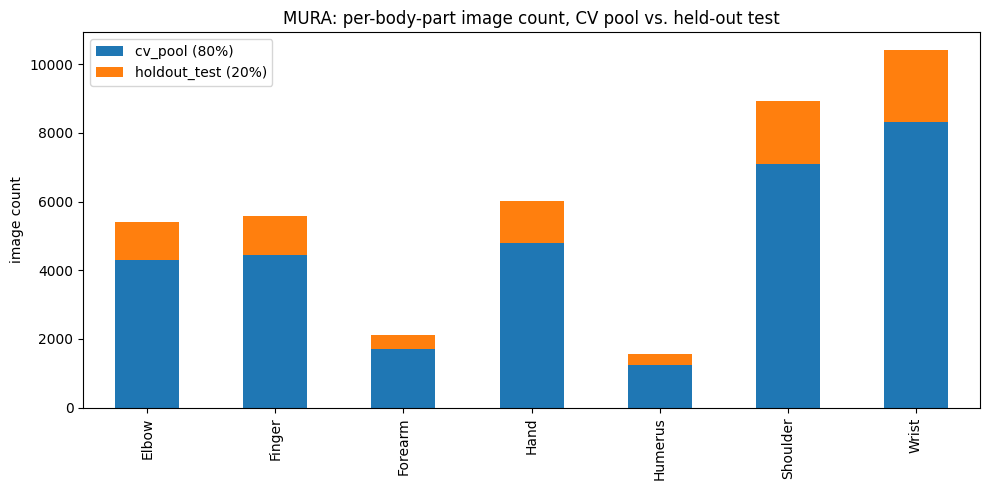


Patients -- CV pool: 9583, holdout: 2384
Images -- CV pool: 31919, holdout: 8086  (20.2% holdout)


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C

index_df = pd.read_csv("/kaggle/working/index.csv")
holdout_df = pd.read_csv("/kaggle/working/splits/holdout_uids.csv")
cv_df = pd.read_csv("/kaggle/working/splits/cv_folds.csv")
label_cols = [c for c in cv_df.columns if c.startswith("label_")]

dist = pd.DataFrame({
    "all_train": index_df[index_df["split"] == "train"][label_cols].sum(),
    "holdout_test (20%)": holdout_df[label_cols].sum(),
    "cv_pool (80%)": cv_df[label_cols].sum(),
})
dist.index = [c.split("_", 2)[-1].replace("_", " ") for c in dist.index]
print(dist)

dist[["cv_pool (80%)", "holdout_test (20%)"]].plot(kind="bar", stacked=True, figsize=(10, 5))
plt.ylabel("image count")
plt.title("MURA: per-body-part image count, CV pool vs. held-out test")
plt.tight_layout()
plt.savefig("/kaggle/working/runs/eda_holdout_vs_pool_mura.png", dpi=120)
plt.show()

print(f"\nPatients -- CV pool: {cv_df['patient_id'].nunique()}, holdout: {holdout_df['patient_id'].nunique()}")
print(f"Images -- CV pool: {len(cv_df)}, holdout: {len(holdout_df)}  "
      f"({len(holdout_df) / (len(cv_df) + len(holdout_df)):.1%} holdout)")


## 6. Pre-cache / normalize images (PNG -> pseudo-RGB PNG cache)


In [26]:
!cd /kaggle/working && python -m src.cache_images


Indexing PNG files under /kaggle/input/datasets/cjinny/mura-v11/MURA-v1.1 ...
Found 40005 files. Caching to /kaggle/working/image_cache ...
  250/40005 (63.4s elapsed)
  500/40005 (123.4s elapsed)
  750/40005 (186.9s elapsed)
  1000/40005 (246.7s elapsed)
  1250/40005 (304.3s elapsed)
  1500/40005 (367.7s elapsed)
  1750/40005 (428.7s elapsed)
  2000/40005 (484.8s elapsed)
  2250/40005 (543.9s elapsed)
  2500/40005 (608.5s elapsed)
  2750/40005 (672.6s elapsed)
  3000/40005 (734.5s elapsed)
  3250/40005 (794.8s elapsed)
  3500/40005 (852.9s elapsed)
  3750/40005 (912.9s elapsed)
  4000/40005 (971.6s elapsed)
  4250/40005 (1030.1s elapsed)
  4500/40005 (1090.2s elapsed)
  4750/40005 (1147.1s elapsed)
  5000/40005 (1203.6s elapsed)
  5250/40005 (1256.8s elapsed)
  5500/40005 (1308.4s elapsed)
  5750/40005 (1357.0s elapsed)
  6000/40005 (1407.9s elapsed)
  6250/40005 (1460.2s elapsed)
  6500/40005 (1509.8s elapsed)
  6750/40005 (1559.2s elapsed)
  7000/40005 (1609.6s elapsed)
  7250/40005

## 7. Model summary (params / FLOPs / inference time) for the chosen backbone


In [27]:
import torch
from src import config as C
from src.models import build_model, input_size_for
from src.models_hybrid import HybridCNNTransformer, HYBRID_INPUT_SIZE
from src.compare_backbones import measure_inference_time

try:
    from thop import profile
    HAS_THOP = True
except ImportError:
    HAS_THOP = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if BEST_BACKBONE.startswith("hybrid_"):
    model = HybridCNNTransformer(pretrained=False).to(device)
    img_size = HYBRID_INPUT_SIZE
else:
    model = build_model(BEST_BACKBONE, pretrained=False).to(device)
    img_size = input_size_for(BEST_BACKBONE)

n_params = sum(p.numel() for p in model.parameters())
flops = None
if HAS_THOP:
    dummy = torch.randn(1, 3, img_size, img_size, device=device)
    flops, _ = profile(model, inputs=(dummy,), verbose=False)
inf_ms = measure_inference_time(model, img_size, device)

print(f"backbone: {BEST_BACKBONE}")
print(f"n_classes: {C.N_CLASSES}  (last-layer neuron count -- the only architectural change vs. Notebook 2)")
print(f"input size: {img_size}x{img_size}")
print(f"params: {n_params / 1e6:.2f}M")
print(f"FLOPs: {(flops / 1e9) if flops else 'n/a'} G")
print(f"inference: {inf_ms:.2f} ms/image (this device)")
del model


backbone: swin_tiny
n_classes: 7  (last-layer neuron count -- the only architectural change vs. Notebook 2)
input size: 224x224
params: 27.52M
FLOPs: 4.371089184 G
inference: 11.95 ms/image (this device)


## 8. Train `BEST_BACKBONE` on every CV fold (2 at a time, one per GPU)

Identical training cell to Notebook 2/4 -- `UNIFESP_DATASET=mura` (set in
step 3) routes `dataset.py` to the PNG loader with path-based uids, and
gives the model a 7-neuron head instead of 22/14.


In [28]:
import subprocess

CV_FOLDS = [0, 1, 2, 3, 4]
CV_FOLDS_CSV = "/kaggle/working/splits/cv_folds.csv"


def launch_cv_fold(fold, gpu_id):
    env = os.environ.copy()
    env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    run_name = f"{BEST_BACKBONE}_cvfold{fold}"
    log = open(f"/kaggle/working/{run_name}.log", "w")
    if BEST_BACKBONE.startswith("hybrid_"):
        loss_variant = "hierarchical" if BEST_BACKBONE == "hybrid_hierarchical" else "plain"
        cmd = ["python", "-m", "src.train_hybrid", "--loss", loss_variant, "--fold", str(fold),
               "--epochs", str(EPOCHS), "--batch_size", "24", "--max_hours", str(MAX_HOURS_PER_FOLD),
               "--folds_csv", CV_FOLDS_CSV, "--run_name", run_name]
    else:
        cmd = ["python", "-m", "src.train", "--backbone", BEST_BACKBONE, "--fold", str(fold),
               "--epochs", str(EPOCHS), "--batch_size", "32", "--max_hours", str(MAX_HOURS_PER_FOLD),
               "--folds_csv", CV_FOLDS_CSV, "--run_name", run_name]
    return subprocess.Popen(cmd, cwd="/kaggle/working", env=env, stdout=log, stderr=subprocess.STDOUT)


for i in range(0, len(CV_FOLDS), 2):
    pair = CV_FOLDS[i:i + 2]
    print(f"\n=== training cv_fold(s) {pair} ===")
    procs = list(zip(pair, [launch_cv_fold(f, gpu) for gpu, f in enumerate(pair)]))
    for fold, p in procs:
        rc = p.wait()
        print(f"[{'ok' if rc == 0 else 'FAILED'}] cv_fold {fold} (exit {rc})")

print("\nAll CV folds done.")



=== training cv_fold(s) [0, 1] ===
[ok] cv_fold 0 (exit 0)
[ok] cv_fold 1 (exit 0)

=== training cv_fold(s) [2, 3] ===
[ok] cv_fold 2 (exit 0)
[ok] cv_fold 3 (exit 0)

=== training cv_fold(s) [4] ===
[ok] cv_fold 4 (exit 0)

All CV folds done.


Check progress any time (run in a new cell while training is in progress):


In [29]:
!tail -n 20 /kaggle/working/{BEST_BACKBONE}_cvfold0.log


epoch 6: train_loss=0.0910 val_loss=0.0832 macro_f1=0.9319 (226.9s)
epoch 7: train_loss=0.0827 val_loss=0.0795 macro_f1=0.9355 (218.2s)
epoch 8: train_loss=0.0747 val_loss=0.0848 macro_f1=0.9331 (223.9s)
epoch 9: train_loss=0.0692 val_loss=0.0978 macro_f1=0.9392 (219.7s)
  -> new best macro_f1=0.9392, saved checkpoint_best.pt
epoch 10: train_loss=0.0610 val_loss=0.0882 macro_f1=0.9226 (223.7s)
epoch 11: train_loss=0.0526 val_loss=0.0794 macro_f1=0.9486 (224.9s)
  -> new best macro_f1=0.9486, saved checkpoint_best.pt
epoch 12: train_loss=0.0473 val_loss=0.0860 macro_f1=0.9493 (223.4s)
  -> new best macro_f1=0.9493, saved checkpoint_best.pt
epoch 13: train_loss=0.0417 val_loss=0.0863 macro_f1=0.9623 (213.3s)
  -> new best macro_f1=0.9623, saved checkpoint_best.pt
epoch 14: train_loss=0.0336 val_loss=0.0890 macro_f1=0.9615 (211.8s)
epoch 15: train_loss=0.0300 val_loss=0.0886 macro_f1=0.9583 (209.5s)
epoch 16: train_loss=0.0253 val_loss=0.0946 macro_f1=0.9609 (209.1s)
epoch 17: train_loss=

## 9. Evaluate every CV-fold checkpoint on the SAME held-out test set


In [30]:
!cd /kaggle/working && python -m src.evaluate_on_holdout --backbone {BEST_BACKBONE} --cv_folds 0,1,2,3,4


indexing PNG files under /kaggle/input/datasets/cjinny/mura-v11/MURA-v1.1 ...
[cv_fold 0] sample_mean_f1=0.9742  macro_f1=0.9570  (epoch 17)
[cv_fold 1] sample_mean_f1=0.9751  macro_f1=0.9594  (epoch 19)
[cv_fold 2] sample_mean_f1=0.9743  macro_f1=0.9564  (epoch 15)
[cv_fold 3] sample_mean_f1=0.9755  macro_f1=0.9617  (epoch 18)
[cv_fold 4] sample_mean_f1=0.9742  macro_f1=0.9558  (epoch 18)

=== swin_tiny: holdout-test performance across 5 cv_fold model(s) ===
      sample_mean_f1  macro_f1  micro_f1  macro_auc  subset_accuracy  kappa_flat
mean        0.974676  0.958075  0.970987   0.997240         0.963517    0.966096
std         0.000597  0.002471  0.001167   0.000428         0.001586    0.001371

Saved: /kaggle/working/runs/holdout_per_fold_swin_tiny.csv
Saved: /kaggle/working/runs/holdout_summary_swin_tiny.csv

=== Classification report (bagged cv_fold ensemble on holdout) ===
              precision    recall  f1-score   support

       Elbow       0.97      0.99      0.98      109

In [31]:
import pandas as pd
summary = pd.read_csv(f"/kaggle/working/runs/holdout_summary_{BEST_BACKBONE}.csv", index_col=0)
print("MURA held-out test performance (mean +/- std across 5 CV-fold models):")
summary


MURA held-out test performance (mean +/- std across 5 CV-fold models):


,sample_mean_f1,macro_f1,micro_f1,macro_auc,subset_accuracy,kappa_flat
mean,0.974676,0.958075,0.970987,0.997240,0.963517,0.966096
std,0.000597,0.002471,0.001167,0.000428,0.001586,0.001371


## 10. Confusion matrix (per-class) + classification report, visualized


              precision    recall  f1-score   support

       Elbow       0.97      0.99      0.98      1091
      Finger       0.98      0.97      0.98      1112
     Forearm       0.90      0.93      0.91       435
        Hand       0.94      0.99      0.97      1197
     Humerus       0.95      0.95      0.95       319
    Shoulder       0.99      1.00      0.99      1846
       Wrist       0.98      0.98      0.98      2086

   micro avg       0.97      0.98      0.98      8086
   macro avg       0.96      0.97      0.96      8086
weighted avg       0.97      0.98      0.98      8086
 samples avg       0.98      0.98      0.98      8086



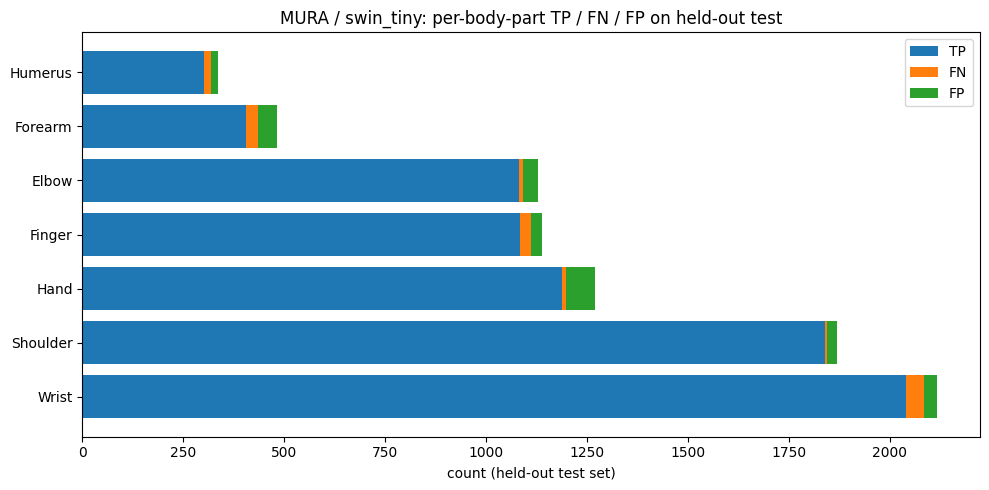

,class,TN,FP,FN,TP,precision,recall
6,Wrist,5968,32,45,2041,0.984563,0.978428
5,Shoulder,6217,23,5,1841,0.987661,0.997291
3,Hand,6817,72,10,1187,0.942812,0.991646
1,Finger,6948,26,29,1083,0.976555,0.973921
0,Elbow,6958,37,9,1082,0.966935,0.991751
2,Forearm,7604,47,30,405,0.896018,0.931034
4,Humerus,7750,17,17,302,0.946708,0.946708


In [32]:
import pandas as pd
import matplotlib.pyplot as plt

with open(f"/kaggle/working/runs/holdout_classification_report_{BEST_BACKBONE}.txt") as f:
    print(f.read())

mcm = pd.read_csv(f"/kaggle/working/runs/holdout_confusion_per_class_{BEST_BACKBONE}.csv")
mcm["precision"] = mcm["TP"] / (mcm["TP"] + mcm["FP"]).replace(0, pd.NA)
mcm["recall"] = mcm["TP"] / (mcm["TP"] + mcm["FN"]).replace(0, pd.NA)
mcm = mcm.sort_values("TP", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(mcm["class"], mcm["TP"], label="TP")
ax.barh(mcm["class"], mcm["FN"], left=mcm["TP"], label="FN")
ax.barh(mcm["class"], mcm["FP"], left=mcm["TP"] + mcm["FN"], label="FP")
ax.set_xlabel("count (held-out test set)")
ax.legend()
plt.title(f"MURA / {BEST_BACKBONE}: per-body-part TP / FN / FP on held-out test")
plt.tight_layout()
plt.savefig(f"/kaggle/working/runs/holdout_confusion_chart_{BEST_BACKBONE}_mura.png", dpi=120)
plt.show()

mcm


## 11. Compare against Notebook 2 (UNIFESP) and Notebook 4 (ChestX-ray14)

Three independent datasets, same exact method -> the strongest
generalization evidence the paper can show. Paste each notebook's
`holdout_summary_{BEST_BACKBONE}.csv` side by side once all three have
finished.


In [33]:
# Example -- fill in once you have all three summaries downloaded:
# import pandas as pd
# unifesp = pd.read_csv("unifesp_holdout_summary_swin_tiny.csv", index_col=0)
# chestxray14 = pd.read_csv("chestxray14_holdout_summary_swin_tiny.csv", index_col=0)
# mura = summary  # from cell above
# pd.concat({"UNIFESP": unifesp["sample_mean_f1"], "ChestX-ray14": chestxray14["sample_mean_f1"],
#            "MURA": mura["sample_mean_f1"]}, axis=1)


## 12. Before this session ends

**Click "Save Version"**, or at minimum download `runs/` in full, plus
`index.csv` and `splits/` -- `/kaggle/working` is wiped when the session
ends.
